# 🔥 AI for IoT – Practical 1: Fire Alarm Detection

## 1. Objective
Build a **binary classification model** that predicts the state of an IoT-connected smoke detector from its environmental sensor readings.

- **Core task:** Logistic Regression
- **Bonus:** XGBoost, and a comparison of the two models

## 2. Dataset
[Kaggle – Smoke Detection Dataset](https://www.kaggle.com/datasets/deepcontractor/smoke-detection-dataset) (`smoke_detection_iot.csv`)

- **Inputs (X):** sensor readings: temperature, humidity, gases (TVOC, eCO2, raw H2, raw ethanol), pressure, particulate matter (PM, NC)
- **Target (y):** `Fire Alarm` → `1` = alarm ON (fire/smoke), `0` = normal conditions

> **On Kaggle:** *Add Input → Datasets →* search "smoke detection dataset" (deepcontractor). The loader below finds the CSV in `/kaggle/input`, or next to the notebook when it runs locally.

---
# 3. Core Task: Logistic Regression Classifier

## A. Setup and Preprocessing

### A.1 Import libraries

In [1]:
import os

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed so that the split and the results can be reproduced

### A.2 Load and inspect the data

In [2]:
# Look for the CSV in the Kaggle inputs first, then next to this notebook
csv_path = None
for root in ["/kaggle/input", "."]:
    for dirpath, _, files in os.walk(root):
        if "smoke_detection_iot.csv" in files:
            csv_path = os.path.join(dirpath, "smoke_detection_iot.csv")
            break
    if csv_path:
        break

assert csv_path is not None, "smoke_detection_iot.csv not found - attach the dataset to the notebook."
print("Loading:", csv_path)

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Loading: .\smoke_detection_iot.csv
Shape: (62630, 16)


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [3]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB


In [4]:
# Number of missing values in each column
df.isnull().sum()

Unnamed: 0        0
UTC               0
Temperature[C]    0
Humidity[%]       0
TVOC[ppb]         0
eCO2[ppm]         0
Raw H2            0
Raw Ethanol       0
Pressure[hPa]     0
PM1.0             0
PM2.5             0
NC0.5             0
NC1.0             0
NC2.5             0
CNT               0
Fire Alarm        0
dtype: int64

#### Handling missing data
`.isnull().sum()` shows the number of missing values per column. The cell below handles them so that the notebook also works on a copy of the data that has gaps:
- a missing **numeric** sensor value is replaced by the **median** of its column (imputation). The median is less affected than the mean by the large sensor spikes recorded during fires;
- any row that is still incomplete is removed.

In [5]:
missing_before = df.isnull().sum().sum()

num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())   # imputation with the median
df = df.dropna()                                            # removal of anything still missing

print(f"Missing values before: {missing_before} | after: {df.isnull().sum().sum()} | rows kept: {len(df)}")

Missing values before: 0 | after: 0 | rows kept: 62630


#### Class balance of the target

            samples  proportion
Fire Alarm                     
0             17873       0.285
1             44757       0.715


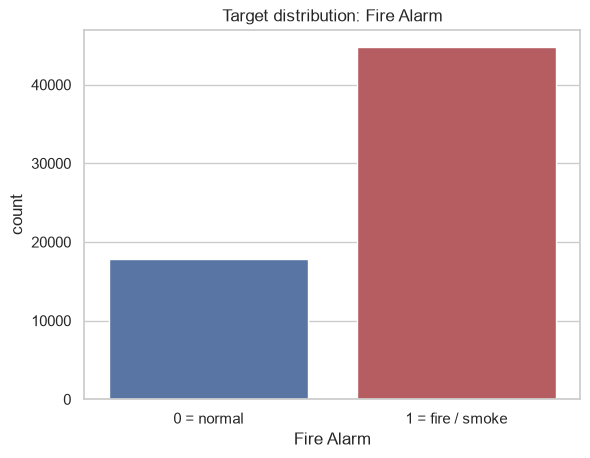

In [6]:
counts = df["Fire Alarm"].value_counts().sort_index()
print(pd.DataFrame({"samples": counts, "proportion": (counts / len(df)).round(3)}))

ax = sns.countplot(x="Fire Alarm", hue="Fire Alarm", data=df, palette=["#4C72B0", "#C44E52"], legend=False)
ax.set_xticks([0, 1], ["0 = normal", "1 = fire / smoke"])
ax.set_title("Target distribution: Fire Alarm")
plt.show()

The two classes are **not balanced**: most samples have the alarm ON. For this reason:
- the train/test split is **stratified**, so the test set keeps the same class proportions;
- the model is judged with **Precision, Recall and F1-Score**, not only Accuracy.

### A.3 Define features (X) and target (y)

`Fire Alarm` is the target `y`. The features `X` are the **12 sensor readings**. Three columns are not sensor measurements and are removed:
- `Unnamed: 0`: the row number of the CSV file;
- `UTC`: the timestamp of the reading;
- `CNT`: a sample counter that restarts at 0 at the start of each recording.

A real detector must decide from what its sensors measure, not from the time or the position of a sample in a file.

In [7]:
TARGET = "Fire Alarm"
DROP_COLS = ["Unnamed: 0", "UTC", "CNT"]   # not sensor measurements

X = df.drop(columns=[TARGET] + DROP_COLS)
y = df[TARGET]

# XGBoost (bonus) does not accept '[', ']' or '<' in feature names: "Temperature[C]" -> "Temperature_C"
X.columns = X.columns.str.replace("[", "_", regex=False).str.replace("]", "", regex=False)

print("Features:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)

Features: ['Temperature_C', 'Humidity_%', 'TVOC_ppb', 'eCO2_ppm', 'Raw H2', 'Raw Ethanol', 'Pressure_hPa', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5']
X shape: (62630, 12) | y shape: (62630,)


### A.4 Split the data (80% training / 20% testing)

The split is done **before** the scaling of A.5. The scaler then computes its mean and standard deviation on the training set only, so nothing from the test set is used during training (no *data leakage*).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,            # 20% for testing, 80% for training
    stratify=y,                # same class proportions in both sets
    random_state=RANDOM_STATE,
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Fire ratio  -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Training set: (50104, 12) | Test set: (12526, 12)
Fire ratio  -> train: 0.715 | test: 0.715


### A.5 Feature scaling with `StandardScaler` (mandatory)

The sensors have very different units and ranges (see the table below). Logistic Regression is trained by an optimisation algorithm and applies the same regularisation to every weight, so features with large values would dominate the others.
`StandardScaler` transforms each feature to **mean 0 and standard deviation 1**: $z = (x - \mu) / \sigma$.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mu and sigma on the training set only
X_test_scaled  = scaler.transform(X_test)        # apply the same mu and sigma to the test set

# Ranges before and after scaling (training set)
pd.DataFrame({
    "mean before": X_train.mean(),
    "std before":  X_train.std(),
    "max before":  X_train.max(),
    "mean after":  X_train_scaled.mean(axis=0),
    "std after":   X_train_scaled.std(axis=0),
}).round(2)

,mean before,std before,max before,mean after,std after
Temperature_C,15.95,14.36,59.93,-0.0,1.0
Humidity_%,48.57,8.82,75.20,-0.0,1.0
TVOC_ppb,1922.88,7755.97,60000.00,-0.0,1.0
eCO2_ppm,667.74,1903.80,60000.00,-0.0,1.0
Raw H2,12942.30,271.17,13803.00,0.0,1.0
Raw Ethanol,19754.25,606.98,21410.00,-0.0,1.0
Pressure_hPa,938.63,1.32,939.86,0.0,1.0
PM1.0,100.89,925.31,14318.17,0.0,1.0
PM2.5,186.07,1991.55,45432.26,-0.0,1.0
NC0.5,490.21,4259.46,61482.03,0.0,1.0


## B. Training and Evaluation

### B.1 Train the Logistic Regression model

In [10]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)   # trained on the scaled features

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

### B.2 Make predictions on the test set

In [11]:
y_pred_lr = log_reg.predict(X_test_scaled)

# First 10 test samples: true label vs predicted label
pd.DataFrame({"true": y_test.values[:10], "predicted": y_pred_lr[:10]}).T

,0,1,2,3,4,5,6,7,8,9
true,1,1,0,0,1,1,0,1,0,1
predicted,1,1,0,1,1,1,0,1,0,1


### B.3 Evaluate performance

- **Accuracy** = (TP + TN) / total: share of correct predictions
- **Precision** = TP / (TP + FP): when the model says *fire*, how often it is right
- **Recall** = TP / (TP + FN): share of the real fires that the model detects
- **F1-Score** = harmonic mean of Precision and Recall

(TP: fire detected · TN: normal recognised · FP: false alarm · FN: missed fire)

In [12]:
def evaluate(name, y_true, y_pred):
    # Compute the four required metrics, print them and return them as a dict
    res = {
        "Model":     name,
        "Accuracy":  metrics.accuracy_score(y_true, y_pred),
        "Precision": metrics.precision_score(y_true, y_pred),
        "Recall":    metrics.recall_score(y_true, y_pred),
        "F1-Score":  metrics.f1_score(y_true, y_pred),
    }
    for k, v in res.items():
        if k != "Model":
            print(f"{k:<10}: {v:.4f}")
    return res


print("=== Logistic Regression ===")
res_lr = evaluate("Logistic Regression", y_test, y_pred_lr)
print("\nDetailed report per class:\n")
print(metrics.classification_report(y_test, y_pred_lr, target_names=["0 = normal", "1 = fire"], digits=4))

=== Logistic Regression ===
Accuracy  : 0.8951
Precision : 0.9090
Recall    : 0.9482
F1-Score  : 0.9281

Detailed report per class:

              precision    recall  f1-score   support

  0 = normal     0.8545    0.7622    0.8057      3575
    1 = fire     0.9090    0.9482    0.9281      8951

    accuracy                         0.8951     12526
   macro avg     0.8817    0.8552    0.8669     12526
weighted avg     0.8934    0.8951    0.8932     12526



### B.4 Visualize results: confusion matrix

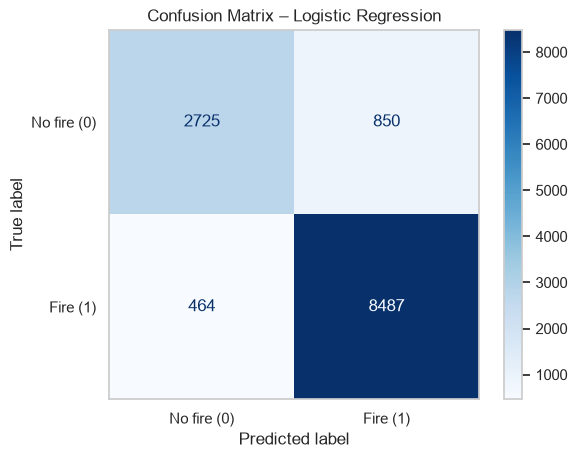

TN = 2725  |  FP (false alarms) = 850  |  FN (missed fires) = 464  |  TP = 8487


In [13]:
def plot_confusion(name, y_true, y_pred, cmap="Blues"):
    # Draw the confusion matrix with readable labels and return it
    cm = metrics.confusion_matrix(y_true, y_pred)
    disp = metrics.ConfusionMatrixDisplay(cm, display_labels=["No fire (0)", "Fire (1)"])
    disp.plot(cmap=cmap, values_format="d")
    plt.title(f"Confusion Matrix – {name}")
    plt.grid(False)
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN = {tn}  |  FP (false alarms) = {fp}  |  FN (missed fires) = {fn}  |  TP = {tp}")
    return cm


cm_lr = plot_confusion("Logistic Regression", y_test, y_pred_lr, cmap="Blues")

#### Reading the results
The test set contains **8,951 real fires** and **3,575 normal samples**.
- **Missed fires (FN = 464, bottom-left cell):** the model detects 8,487 of the 8,951 fires, so **Recall = 8,487 / 8,951 = 0.9482**.
- **False alarms (FP = 850, top-right cell):** 850 of the 3,575 normal samples are classified as fire. Only 76.2% of the normal situations are recognised (Recall of class 0 = 0.7622).
- **Precision = 8,487 / (8,487 + 850) = 0.9090:** about 9 alarms out of 10 are real fires.

---
# 🏆 Bonus Challenge: XGBoost

### 1. Implement XGBoost
XGBoost builds an ensemble of decision trees one after the other; each new tree corrects the errors of the previous ones.
A tree splits on threshold values (for example `TVOC_ppb > 1000`), and these splits do not change when a feature is rescaled. XGBoost is therefore **not sensitive to feature scaling**, so it is trained on the **raw features**.

In [14]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,        # number of trees
    max_depth=6,             # maximum depth of each tree
    learning_rate=0.1,       # contribution of each new tree
    subsample=0.9,           # share of the rows used by each tree
    colsample_bytree=0.9,    # share of the features used by each tree
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

### 2. Train and evaluate (same train/test split, same metrics)

In [15]:
xgb.fit(X_train, y_train)          # same X_train / y_train as Logistic Regression, without scaling
y_pred_xgb = xgb.predict(X_test)

print("=== XGBoost ===")
res_xgb = evaluate("XGBoost", y_test, y_pred_xgb)
print("\nDetailed report per class:\n")
print(metrics.classification_report(y_test, y_pred_xgb, target_names=["0 = normal", "1 = fire"], digits=4))

=== XGBoost ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000

Detailed report per class:

              precision    recall  f1-score   support

  0 = normal     1.0000    1.0000    1.0000      3575
    1 = fire     1.0000    1.0000    1.0000      8951

    accuracy                         1.0000     12526
   macro avg     1.0000    1.0000    1.0000     12526
weighted avg     1.0000    1.0000    1.0000     12526



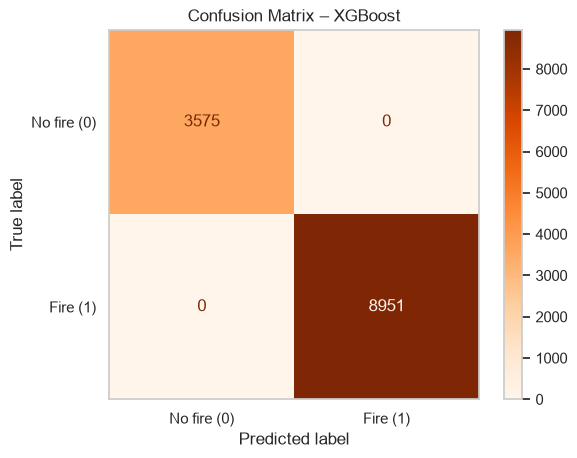

TN = 3575  |  FP (false alarms) = 0  |  FN (missed fires) = 0  |  TP = 8951


In [16]:
cm_xgb = plot_confusion("XGBoost", y_test, y_pred_xgb, cmap="Oranges")

### 3. Compare and analyze

,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Model,,,,,,
Logistic Regression,0.8951,0.909,0.9482,0.9281,464,850
XGBoost,1.0000,1.000,1.0000,1.0000,0,0


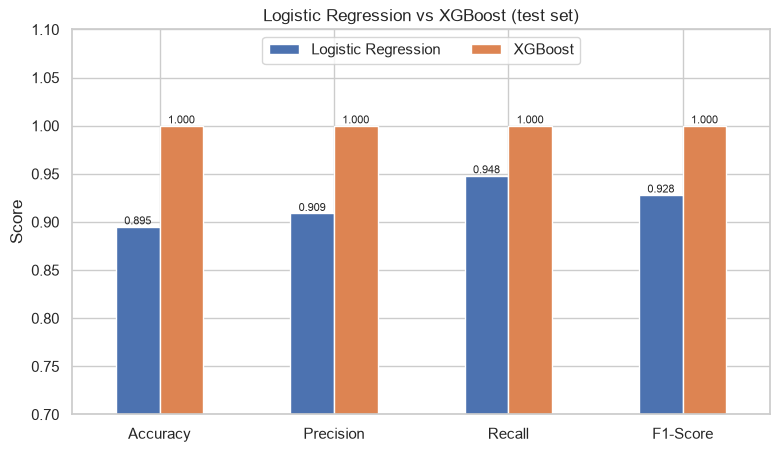

Model with the higher Recall: XGBoost


In [17]:
results = pd.DataFrame([res_lr, res_xgb]).set_index("Model")
results["Missed fires (FN)"] = [cm_lr[1, 0], cm_xgb[1, 0]]
results["False alarms (FP)"] = [cm_lr[0, 1], cm_xgb[0, 1]]
display(results.round(4))

ax = results[["Accuracy", "Precision", "Recall", "F1-Score"]].T.plot(
    kind="bar", figsize=(9, 5), rot=0, color=["#4C72B0", "#DD8452"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.title("Logistic Regression vs XGBoost (test set)")
plt.ylabel("Score")
plt.ylim(0.7, 1.1)
plt.legend(loc="upper center", ncol=2)
plt.show()

print("Model with the higher Recall:", results["Recall"].idxmax())

#### Simplicity and speed vs complexity
The cell below measures the training time, the prediction time on the whole test set, and the size of each trained model.
The times depend on the machine, so they change a little from one run to another.

In [18]:
import time

def mean_time_ms(fn, repeat):
    # Average run time of fn() in milliseconds
    start = time.perf_counter()
    for _ in range(repeat):
        fn()
    return (time.perf_counter() - start) / repeat * 1000

n_lr_params = log_reg.coef_.size + log_reg.intercept_.size          # one weight per feature + the bias
xgb_nodes = len(xgb.get_booster().trees_to_dataframe())             # all nodes of all trees

complexity = pd.DataFrame({
    "Train time (ms)": [
        mean_time_ms(lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train), 3),
        mean_time_ms(lambda: XGBClassifier(**xgb.get_params()).fit(X_train, y_train), 1),
    ],
    "Predict test set (ms)": [
        mean_time_ms(lambda: log_reg.predict(X_test_scaled), 10),
        mean_time_ms(lambda: xgb.predict(X_test), 10),
    ],
    "Model size": [
        f"{n_lr_params} numbers ({log_reg.coef_.size} weights + 1 bias)",
        f"{xgb.n_estimators} trees, {xgb_nodes} nodes",
    ],
}, index=["Logistic Regression", "XGBoost"])
complexity.round(2)

,Train time (ms),Predict test set (ms),Model size
Logistic Regression,97.39,0.50,13 numbers (12 weights + 1 bias)
XGBoost,828.64,14.47,"300 trees, 4922 nodes"


#### Which model has the higher Recall?
**XGBoost**, with **Recall = 1.0000** (0 missed fires), against **0.9482** for Logistic Regression (464 missed fires). XGBoost is also better on every other metric: 0 false alarms against 850.

The relation between the sensors and the alarm is not linear. The gas and particle sensors stay close to 0 most of the time and jump to very large values during some events (see the `max before` column in A.5).
A tree can learn thresholds and combinations of sensors. Logistic Regression can only draw one straight boundary: a weighted sum of the scaled features compared to a threshold.

> **Read the 1.0000 with care.** The sensors record **one sample per second**, and a random split puts readings taken a few seconds apart in the training set and in the test set.
> The deeper analysis below (D.3 to D.5) shows that this test set is much easier than data from a new recording.

#### Why is minimizing False Negatives crucial in fire detection?
- A **False Negative** is a real fire with **no alarm**. Nobody is warned, the evacuation and the call to the firefighters are delayed, and the fire keeps spreading. The result can be injuries, deaths and destroyed property: the cost is **very high and cannot be undone**.
- A **False Positive** is a **false alarm**. It is annoying and has a cost (an unnecessary evacuation or call-out), but it is **recoverable**.
- So, for a fire alarm, **Recall on the fire class is the most important metric**. Precision still matters: too many false alarms make people ignore or unplug the detector.

#### Trade-offs
| Criterion | Logistic Regression | XGBoost |
|---|---|---|
| Recall / F1-Score (test set) | 0.9482 / 0.9281 | **1.0000 / 1.0000** |
| Missed fires / false alarms | 464 / 850 | **0 / 0** |
| Feature scaling | Required (`StandardScaler`) | Not required |
| Training time (this run) | **97 ms** | 829 ms (about 8× slower) |
| Prediction time for the 12,526 test samples (this run) | **0.50 ms** | 14 ms (about 30× slower) |
| Model size | **13 numbers** (12 weights + 1 bias) | 300 trees, 4,922 nodes |
| Interpretability | **High**: the sign and size of each weight show the effect of each sensor | Lower: needs feature importance or SHAP |
| Non-linear relations | Not captured | Captured |

- **Logistic Regression → simplicity & speed.** It trains and predicts much faster, its whole model is 13 numbers, and one prediction is a weighted sum followed by a sigmoid. It is easy to explain and to run on a small IoT node. The price is lower performance: 464 missed fires and 850 false alarms on this test set.
- **XGBoost → higher performance, more complexity.** It gives the best detection here, but it needs 300 trees (4,922 nodes), more memory and more computation for each prediction, and its decisions are harder to explain.

---
# 🔬 Deeper analysis

The statement is answered above. This part goes further and asks four questions:
1. **What did the models learn?** Which sensors drive their decisions?
2. **Can Logistic Regression miss fewer fires?** A `log1p` transform and a lower decision threshold.
3. **Is the random 80/20 split realistic?** Are the test samples really new to the model?
4. **How many independent recordings does the dataset contain, and do the models work on a recording they have never seen?**

## D.1 What did the models learn?

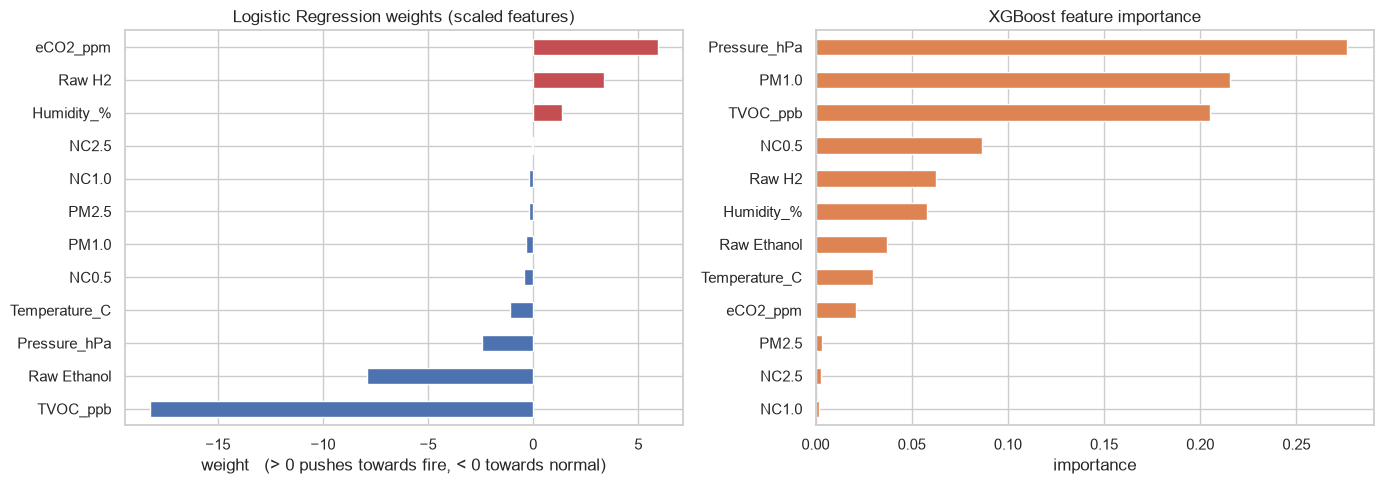

,LR weight,XGBoost importance,correlation with Fire Alarm
TVOC_ppb,-18.230,0.205,-0.215
Raw Ethanol,-7.896,0.037,-0.341
Pressure_hPa,-2.428,0.276,0.250
Temperature_C,-1.106,0.030,-0.164
NC0.5,-0.454,0.086,-0.128
PM1.0,-0.331,0.215,-0.111
PM2.5,-0.195,0.003,-0.085
NC1.0,-0.184,0.002,-0.083
NC2.5,-0.068,0.003,-0.058
Humidity_%,1.378,0.058,0.400


In [19]:
# Logistic Regression: one weight per scaled sensor. XGBoost: importance of each sensor in the trees
coefs = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()
importance = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
coefs.plot(kind="barh", ax=axes[0], color=np.where(coefs > 0, "#C44E52", "#4C72B0"))
axes[0].set_title("Logistic Regression weights (scaled features)")
axes[0].set_xlabel("weight   (> 0 pushes towards fire, < 0 towards normal)")
importance.plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("XGBoost feature importance")
axes[1].set_xlabel("importance")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "LR weight": coefs,
    "XGBoost importance": importance,
    "correlation with Fire Alarm": X.corrwith(y),
}).sort_values("LR weight").round(3)

In [20]:
# TVOC, the sensor with the largest Logistic Regression weight, in normal conditions (0) and during alarms (1)
display(df.groupby("Fire Alarm")["TVOC[ppb]"].describe(percentiles=[0.5, 0.9]).round(0))

# Correlation between the four gas sensors
X[["TVOC_ppb", "eCO2_ppm", "Raw H2", "Raw Ethanol"]].corr().round(2)

,count,mean,std,min,50%,90%,max
Fire Alarm,,,,,,,
0,17873.0,4597.0,14256.0,0.0,86.0,9008.0,60000.0
1,44757.0,882.0,549.0,0.0,1103.0,1343.0,18062.0


,TVOC_ppb,eCO2_ppm,Raw H2,Raw Ethanol
TVOC_ppb,1.00,0.61,-0.65,-0.67
eCO2_ppm,0.61,1.00,-0.68,-0.51
Raw H2,-0.65,-0.68,1.00,0.63
Raw Ethanol,-0.67,-0.51,0.63,1.00


#### What the weights show
- Logistic Regression relies mostly on **TVOC** (weight −18.2), **Raw Ethanol** (−7.9) and **eCO2** (+5.9). XGBoost relies mostly on **Pressure** (0.276), **PM1.0** (0.215) and **TVOC** (0.205).
- **TVOC has a negative weight**: for the model, more volatile organic compounds means *less* fire. The table above shows why. During alarms TVOC stays in a narrow range (median 1,103 ppb, 90% of the values below 1,343 ppb).
  In normal conditions it is usually low (median 86 ppb), but 10% of the values are above 9,008 ppb and go up to 60,000 ppb. These extreme normal values dominate the linear model. D.2 reduces their effect with a log transform.
- **Temperature also has a negative weight (−1.1)**: the model treats hot air as a sign of *normal* conditions, which is the opposite of what we expect from a fire. D.4 shows where this comes from.
- TVOC, eCO2, Raw H2 and Raw Ethanol are strongly correlated with each other (|r| between 0.51 and 0.68). With correlated features, the weights share the effect and can take opposite signs, so a single weight should not be over-interpreted.

## D.2 Can Logistic Regression miss fewer fires?

**a) `log1p` transform of the skewed sensors.** `TVOC`, `eCO2`, `PM` and `NC` are close to 0 most of the time but jump to tens of thousands during some events.
On such a scale a linear model mostly "sees" the extreme values. `log1p(x) = log(1 + x)` compresses the large values and spreads out the small ones.

**b) Lower decision threshold.** By default the model answers *fire* when `P(fire) ≥ 0.5`. A missed fire costs much more than a false alarm, so the threshold is lowered.
It is chosen **on the training set only**, from 5-fold cross-validated probabilities: the highest threshold that still gives **Recall ≥ 0.99**. The test set is never used to choose it.

Both steps are put in a `Pipeline` with the scaler, so everything is fitted on the training data only.

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Skewed, non-negative sensors that get the log transform
SKEWED = ["TVOC_ppb", "eCO2_ppm", "PM1.0", "PM2.5", "NC0.5", "NC1.0", "NC2.5"]

def make_lr():
    # StandardScaler -> Logistic Regression (the model of the core task, as a pipeline)
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

def make_lr_log():
    # log1p on the skewed sensors -> StandardScaler on all features -> Logistic Regression
    log_step = ColumnTransformer([("log", FunctionTransformer(np.log1p), SKEWED)], remainder="passthrough")
    return make_pipeline(log_step, StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

# Skewness before / after the log transform (0 = symmetric distribution)
pd.DataFrame({"skew before": X_train[SKEWED].skew(), "skew after log1p": np.log1p(X_train[SKEWED]).skew()}).round(1)

,skew before,skew after log1p
TVOC_ppb,6.8,-1.0
eCO2_ppm,12.8,5.6
PM1.0,10.7,6.2
PM2.5,14.1,6.4
NC0.5,10.0,4.4
NC1.0,14.4,6.4
NC2.5,17.7,8.5


In [22]:
# (a) Logistic Regression + log1p, default threshold 0.5
lr_log = make_lr_log().fit(X_train, y_train)   # the pipeline scales internally -> raw features as input
y_pred_lr_log = lr_log.predict(X_test)

print("=== Logistic Regression + log1p (threshold 0.5) ===")
res_lr_log = evaluate("LR + log1p", y_test, y_pred_lr_log)

=== Logistic Regression + log1p (threshold 0.5) ===
Accuracy  : 0.9369
Precision : 0.9380
Recall    : 0.9763
F1-Score  : 0.9568


Chosen threshold: 0.376  (instead of 0.5)


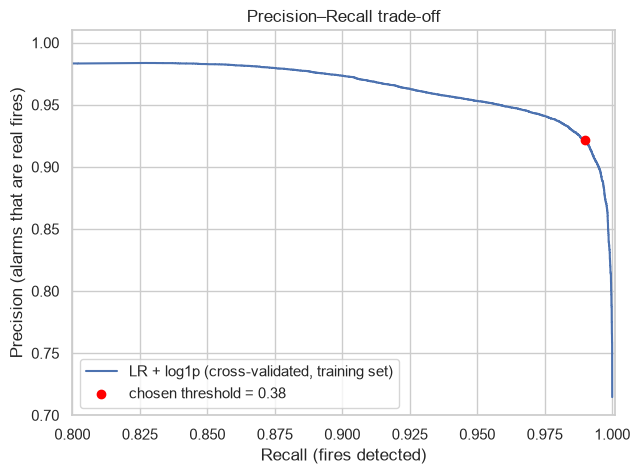

In [23]:
# (b) Choose the threshold on the TRAINING set with cross-validated probabilities
TARGET_RECALL = 0.99
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
proba_cv = cross_val_predict(make_lr_log(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec_cv, rec_cv, thr_cv = metrics.precision_recall_curve(y_train, proba_cv)
i_best = np.where(rec_cv[:-1] >= TARGET_RECALL)[0][-1]   # highest threshold that keeps Recall >= 0.99
best_threshold = thr_cv[i_best]
print(f"Chosen threshold: {best_threshold:.3f}  (instead of 0.5)")

plt.figure(figsize=(7, 5))
plt.plot(rec_cv, prec_cv, label="LR + log1p (cross-validated, training set)")
plt.scatter(rec_cv[i_best], prec_cv[i_best], color="red", zorder=3, label=f"chosen threshold = {best_threshold:.2f}")
plt.xlabel("Recall (fires detected)")
plt.ylabel("Precision (alarms that are real fires)")
plt.title("Precision–Recall trade-off")
plt.xlim(0.8, 1.001)
plt.ylim(0.7, 1.01)
plt.legend()
plt.show()

=== Logistic Regression + log1p (threshold 0.38) ===
Accuracy  : 0.9313
Precision : 0.9221
Recall    : 0.9873
F1-Score  : 0.9535


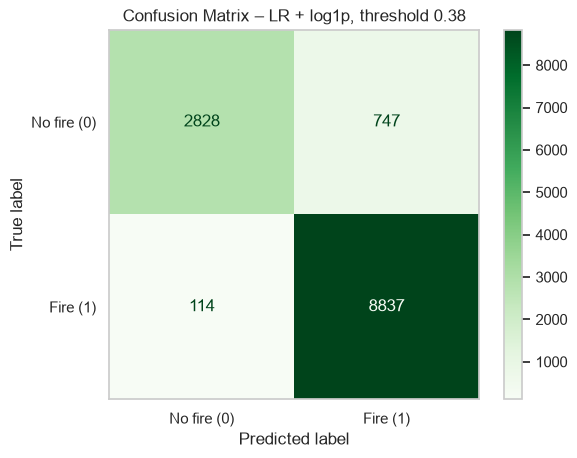

TN = 2828  |  FP (false alarms) = 747  |  FN (missed fires) = 114  |  TP = 8837


In [24]:
# Apply the chosen threshold to the TEST set
y_pred_lr_thr = (lr_log.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)

print(f"=== Logistic Regression + log1p (threshold {best_threshold:.2f}) ===")
res_lr_thr = evaluate(f"LR + log1p + threshold {best_threshold:.2f}", y_test, y_pred_lr_thr)
cm_lr_thr = plot_confusion(f"LR + log1p, threshold {best_threshold:.2f}", y_test, y_pred_lr_thr, cmap="Greens")

In [25]:
# All models on the random 80/20 split
preds = {"Logistic Regression": y_pred_lr, "LR + log1p": y_pred_lr_log,
         res_lr_thr["Model"]: y_pred_lr_thr, "XGBoost": y_pred_xgb}
results_all = pd.DataFrame([res_lr, res_lr_log, res_lr_thr, res_xgb]).set_index("Model")
results_all["Missed fires (FN)"] = [metrics.confusion_matrix(y_test, p)[1, 0] for p in preds.values()]
results_all["False alarms (FP)"] = [metrics.confusion_matrix(y_test, p)[0, 1] for p in preds.values()]
results_all.round(4)

,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Model,,,,,,
Logistic Regression,0.8951,0.9090,0.9482,0.9281,464,850
LR + log1p,0.9369,0.9380,0.9763,0.9568,212,578
LR + log1p + threshold 0.38,0.9313,0.9221,0.9873,0.9535,114,747
XGBoost,1.0000,1.0000,1.0000,1.0000,0,0


#### What the two changes bring (random split)
- **log1p alone improves both errors:** missed fires 464 → **212** and false alarms 850 → **578**. Accuracy goes from 0.8951 to 0.9369 and F1-Score from 0.9281 to 0.9568.
- **Lowering the threshold to 0.38** raises Recall to **0.9873**: only **114 missed fires**, 4.1 times fewer than the baseline. Recall on the test set is close to the 0.99 target chosen on the training set.
- The price is the precision/recall trade-off: false alarms go up from 578 to 747 (still fewer than the 850 of the baseline), and Precision goes down from 0.9380 to 0.9221.
- For a fire alarm, this trade is the right one: a few more false alarms for far fewer missed fires.

## D.3 Is the random 80/20 split realistic?

The sensors record **one sample per second**, and two readings taken one second apart are almost identical. A random split puts some readings in the training set and their neighbours, a few seconds later, in the test set.

**Test: a 1-Nearest-Neighbour "model".** 1-NN learns no rule: for each test sample it **copies the label of the most similar training sample**.
If it scores almost perfectly, the test set mostly contains near-copies of training samples. We also measure **how far apart in time** the test sample and the copied training sample were recorded.

In [26]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1).fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print("=== 1-NN (copies the label of the nearest training sample) ===")
res_knn = evaluate("1-NN", y_test, y_pred_knn)

# Which training sample was copied, and how far away in time was it recorded?
nn_idx = knn.kneighbors(X_test_scaled, n_neighbors=1, return_distance=False)[:, 0]
nn_rows = X_train.index[nn_idx]
time_gap = np.abs(df.loc[X_test.index, "UTC"].values - df.loc[nn_rows, "UTC"].values)

print(f"\nMedian time gap to the copied training sample : {np.median(time_gap):.0f} s")
print(f"Copied sample recorded within 5 s             : {(time_gap <= 5).mean():.1%}")
print(f"Copied sample recorded within 60 s            : {(time_gap <= 60).mean():.1%}")

=== 1-NN (copies the label of the nearest training sample) ===
Accuracy  : 0.9989
Precision : 0.9988
Recall    : 0.9997
F1-Score  : 0.9992



Median time gap to the copied training sample : 3 s
Copied sample recorded within 5 s             : 51.3%
Copied sample recorded within 60 s            : 74.5%


#### The random split mostly tests memory
- 1-NN learns no rule at all, yet it reaches **Accuracy 0.9989** and **Recall 0.9997**: far better than Logistic Regression, and almost as good as XGBoost.
- The training sample it copies was recorded a **median of 3 s** away from the test sample: within 5 s in 51.3% of the cases and within 60 s in 74.5%.
- So most test samples have a near-identical neighbour, recorded a few seconds earlier or later, in the training set. The random split measures how well a model **recognises readings it has almost seen**, not how well it **detects a new fire**. This is called **temporal leakage**, and it is why XGBoost can reach 1.0000.

## D.4 Data audit: how many independent recordings?

The counter `CNT` restarts at 0 at the start of each **recording session**, so the sessions can be found in the data.

In [27]:
# A new session starts each time the sample counter CNT goes back down
session = (df["CNT"].diff() < 0).cumsum()

sessions_info = df.assign(session=session).groupby("session").agg(
    samples=("Fire Alarm", "size"),
    fires=("Fire Alarm", "sum"),
    start=("UTC", "min"),
    end=("UTC", "max"),
)
sessions_info["fire ratio"] = (sessions_info["fires"] / sessions_info["samples"]).round(3)
sessions_info["start"] = pd.to_datetime(sessions_info["start"], unit="s")
sessions_info["end"] = pd.to_datetime(sessions_info["end"], unit="s")
sessions_info

,samples,fires,start,end,fire ratio
session,,,,,
0,24994,21816,2022-06-09 00:08:51,2022-06-09 07:05:24,0.873
1,24994,21816,2022-06-09 07:55:43,2022-06-09 14:52:16,0.873
2,1154,1121,2022-06-10 23:16:45,2022-06-10 23:35:58,0.971
3,5744,2,2022-06-08 18:16:27,2022-06-08 19:52:10,0.000
4,5744,2,2022-06-13 12:45:08,2022-06-13 14:20:51,0.000


Some sessions have **exactly the same number of samples and of fires**. The cell below compares every such pair **row by row**: for each sensor, the share of rows where the two sessions hold exactly the same value.

In [28]:
SENSORS = df.columns.drop(["Unnamed: 0", "UTC", "CNT", "Fire Alarm"])

def session_rows(s):
    return df[session == s].reset_index(drop=True)

same_rows, twins = {}, {}
ids = sessions_info.index
for i, a in enumerate(ids):
    for b in ids[i + 1:]:
        if sessions_info.loc[a, "samples"] != sessions_info.loc[b, "samples"]:
            continue
        A, B = session_rows(a), session_rows(b)
        same = (A[SENSORS] == B[SENSORS]).mean()                       # share of identical rows, per sensor
        same["Fire Alarm (label)"] = (A["Fire Alarm"] == B["Fire Alarm"]).mean()
        same_rows[f"session {a} vs {b}"] = same
        if (same.drop("Temperature[C]") == 1).all():                  # identical except the temperature
            twins[b] = a

print("Twin sessions (identical except the temperature):", [(int(a), int(b)) for b, a in twins.items()])
pd.DataFrame(same_rows).round(3)

Twin sessions (identical except the temperature): [(0, 1), (3, 4)]


,session 0 vs 1,session 3 vs 4
Temperature[C],0.0,0.0
Humidity[%],1.0,1.0
TVOC[ppb],1.0,1.0
eCO2[ppm],1.0,1.0
Raw H2,1.0,1.0
Raw Ethanol,1.0,1.0
Pressure[hPa],1.0,1.0
PM1.0,1.0,1.0
PM2.5,1.0,1.0
NC0.5,1.0,1.0


In [29]:
# How often does a sensor change direction (up <-> down) from one sample to the next?
# A real sensor is noisy and changes direction often; a smooth artificial curve almost never does.
def direction_changes(values):
    steps = np.diff(values)
    steps = steps[steps != 0]                     # ignore samples where the value does not move
    return (np.diff(np.sign(steps)) != 0).mean()

pd.DataFrame({s: {c: direction_changes(session_rows(s)[c].values)
                  for c in ["Temperature[C]", "Humidity[%]", "Raw H2", "Pressure[hPa]"]}
              for s in sessions_info.index}).T.rename_axis("session").round(3)

,Temperature[C],Humidity[%],Raw H2,Pressure[hPa]
session,,,,
0,0.000,0.053,0.647,0.532
1,0.115,0.053,0.647,0.532
2,0.162,0.232,0.374,0.498
3,0.136,0.141,0.551,0.507
4,0.001,0.141,0.551,0.507


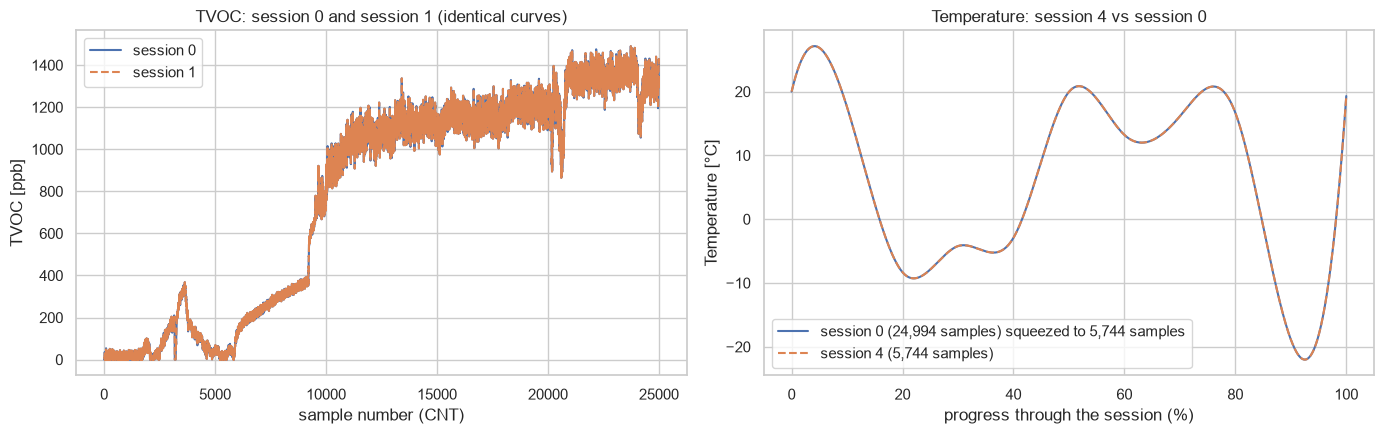

Session 4 temperature vs squeezed session 0 temperature: max |difference| = 0.0010 °C


,"mean T, normal (°C)","mean T, fire (°C)"
session,,
0,21.9,3.9
1,16.5,24.1
2,21.7,34.6
3,33.8,27.3
4,6.2,20.2


In [30]:
# Twin sessions and the temperature curve
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: one sensor of session 0 and of its twin, session 1
for s, style in [(0, "-"), (1, "--")]:
    rows = session_rows(s)
    axes[0].plot(rows["CNT"], rows["TVOC[ppb]"], style, label=f"session {s}")
axes[0].set_title("TVOC: session 0 and session 1 (identical curves)")
axes[0].set_xlabel("sample number (CNT)")
axes[0].set_ylabel("TVOC [ppb]")
axes[0].legend()

# Right: temperature of session 4 vs the temperature curve of session 0 squeezed to the same length
t0 = session_rows(0)["Temperature[C]"].values
t4 = session_rows(4)["Temperature[C]"].values
t0_squeezed = np.interp(np.linspace(0, 1, len(t4)), np.linspace(0, 1, len(t0)), t0)
progress = np.linspace(0, 100, len(t4))
axes[1].plot(progress, t0_squeezed, label=f"session 0 ({len(t0):,} samples) squeezed to {len(t4):,} samples")
axes[1].plot(progress, t4, "--", label=f"session 4 ({len(t4):,} samples)")
axes[1].set_title("Temperature: session 4 vs session 0")
axes[1].set_xlabel("progress through the session (%)")
axes[1].set_ylabel("Temperature [°C]")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Session 4 temperature vs squeezed session 0 temperature: max |difference| = {np.abs(t0_squeezed - t4).max():.4f} °C")

# Mean temperature during normal conditions and during fires, per session
temp_by_label = df.assign(session=session).pivot_table(index="session", columns="Fire Alarm",
                                                       values="Temperature[C]", aggfunc="mean")
temp_by_label.columns = ["mean T, normal (°C)", "mean T, fire (°C)"]
temp_by_label.round(1)

#### What the audit shows
- The data contains **5 sessions**. Sessions 3 and 4 are normal conditions (2 fire samples each); sessions 0, 1 and 2 are mostly fire/smoke.
- **Sessions 0 and 1 are twins, and so are sessions 3 and 4.** For 11 of the 12 sensors and for the label, every row is exactly the same. Only the temperature differs.
- In sessions 0 and 4 the temperature is a **smooth artificial curve**, not a measurement:
  - it almost never changes direction from one sample to the next (0.000 and 0.001), while the other sensors do it far more often (0.053 to 0.647). The temperature of sessions 1, 2 and 3 behaves like a real sensor (0.115 to 0.162);
  - session 4 holds the same curve as session 0, squeezed from 24,994 to 5,744 samples (largest difference: 0.001 °C);
  - this curve goes down to −22 °C, and in session 0 the mean temperature is **3.9 °C during fires** and 21.9 °C in normal conditions. In the sessions with a real temperature, fires are hotter: 24.1 vs 16.5 °C in session 1, and 34.6 vs 21.7 °C in session 2.

**Consequences**
- **30,738 of the 62,630 rows (49%)** repeat other rows with only the temperature changed. The dataset contains only **3 independent recordings**.
- The artificial temperature is the likely reason for the negative temperature weight of D.1: in session 0, 21,816 fire samples have a mean temperature of 3.9 °C.
- The twins make the random split even easier: a test row can have its twin, with the same values except the temperature, in the training set.

## D.5 Do the models work on a recording they have never seen?

A deployed detector will meet new rooms and new fires. To imitate this, the models are trained on some groups of data and tested on a group they have never seen (`LeaveOneGroupOut`). The predictions of all folds are put together and scored on the whole dataset.

Two groupings are compared:
- **Leave one session out:** the 5 sessions of D.4. The two sessions of a twin pair can end up on different sides: one in training, the other in testing.
- **Leave one recording out:** the two sessions of a twin pair stay together, which leaves **3 independent recordings**. This is the honest test.

As a check, XGBoost is also run *leave one session out* **without the temperature**, the only column that differs between twin sessions.

In [31]:
from sklearn.model_selection import LeaveOneGroupOut

recording = session.replace(twins)   # both sessions of a twin pair get the same recording number

models_group = {
    "Logistic Regression": make_lr,
    "LR + log1p": make_lr_log,
    "XGBoost": lambda: XGBClassifier(**xgb.get_params()),
}

def group_cv(groups, models, features):
    # Train on all groups but one, predict the held-out group, repeat for every group
    overall, per_group = {}, {}
    for name, make_model in models.items():
        y_oof = np.zeros(len(y), dtype=int)          # out-of-fold predictions
        acc = {}
        for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups=groups):
            model = make_model().fit(X.iloc[train_idx][features], y.iloc[train_idx])
            y_oof[test_idx] = model.predict(X.iloc[test_idx][features])
            acc[groups.iloc[test_idx[0]]] = metrics.accuracy_score(y.iloc[test_idx], y_oof[test_idx])
        tn, fp, fn, tp = metrics.confusion_matrix(y, y_oof).ravel()
        overall[name] = {"Accuracy": metrics.accuracy_score(y, y_oof), "Precision": metrics.precision_score(y, y_oof, zero_division=0),
                         "Recall": metrics.recall_score(y, y_oof), "F1-Score": metrics.f1_score(y, y_oof),
                         "Missed fires (FN)": fn, "False alarms (FP)": fp}
        per_group[name] = acc
    return pd.DataFrame.from_dict(overall, orient="index"), pd.DataFrame(per_group)

all_features = list(X.columns)
loso, loso_acc = group_cv(session.loc[X.index], models_group, all_features)
loro, loro_acc = group_cv(recording.loc[X.index], models_group, all_features)
no_temp = [c for c in all_features if c != "Temperature_C"]
_, loso_acc_no_temp = group_cv(session.loc[X.index], {"XGBoost without temperature": models_group["XGBoost"]}, no_temp)

print(f"=== Leave one session out (5 sessions) – {len(y):,} samples, {y.sum():,} fires ===")
display(loso.round(4))
print(f"=== Leave one recording out (3 recordings) ===")
display(loro.round(4))

=== Leave one session out (5 sessions) – 62,630 samples, 44,757 fires ===


,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Logistic Regression,0.5741,0.8457,0.4943,0.6239,22635,4036
LR + log1p,0.7411,0.8539,0.7694,0.8095,10319,5894
XGBoost,0.8690,0.9448,0.8674,0.9044,5935,2270


=== Leave one recording out (3 recordings) ===


,Accuracy,Precision,Recall,F1-Score,Missed fires (FN),False alarms (FP)
Logistic Regression,0.1046,0.0143,0.0037,0.0059,44590,11486
LR + log1p,0.1162,0.0004,0.0001,0.0001,44753,10598
XGBoost,0.1090,0.0294,0.0077,0.0122,44412,11393


In [32]:
# Accuracy on each held-out group, with the share of fires in that group
acc_session = loso_acc.join(loso_acc_no_temp)
acc_session["fire ratio"] = sessions_info["fire ratio"]
acc_session.index.name = "held-out session"
print("Leave one session out – accuracy per held-out session")
display(acc_session.round(3))

acc_recording = loro_acc.copy()
acc_recording["sessions"] = [", ".join(str(s) for s in sorted(session[recording == r].unique())) for r in acc_recording.index]
acc_recording["fire ratio"] = [y[recording.loc[X.index] == r].mean() for r in acc_recording.index]
acc_recording.index.name = "held-out recording"
print("Leave one recording out – accuracy per held-out recording")
display(acc_recording.round(3))

Leave one session out – accuracy per held-out session


,Logistic Regression,LR + log1p,XGBoost,XGBoost without temperature,fire ratio
held-out session,,,,,
0,0.271,0.792,0.901,1.000,0.873
1,0.734,0.759,0.907,1.000,0.873
2,0.168,0.029,0.029,0.029,0.971
3,0.967,0.922,0.605,1.000,0.000
4,0.887,0.402,1.000,1.000,0.000


Leave one recording out – accuracy per held-out recording


,Logistic Regression,LR + log1p,XGBoost,sessions,fire ratio
held-out recording,,,,,
0,0.127,0.127,0.134,"0, 1",0.873
2,0.168,0.029,0.029,2,0.971
3,0.000,0.077,0.008,"3, 4",0.000


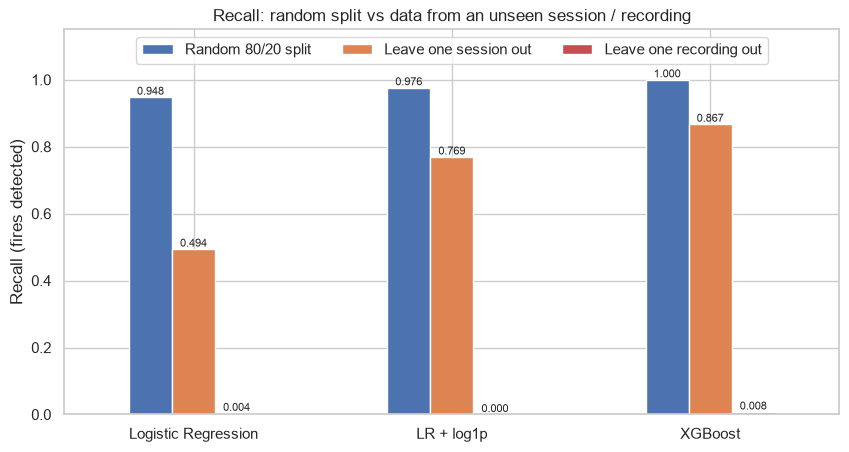

In [33]:
# Recall of each model under the three evaluations
recall_cmp = pd.DataFrame({
    "Random 80/20 split": [res_lr["Recall"], res_lr_log["Recall"], res_xgb["Recall"]],
    "Leave one session out": loso["Recall"].values,
    "Leave one recording out": loro["Recall"].values,
}, index=list(models_group))

ax = recall_cmp.plot(kind="bar", figsize=(10, 5), rot=0, color=["#4C72B0", "#DD8452", "#C44E52"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.title("Recall: random split vs data from an unseen session / recording")
plt.ylabel("Recall (fires detected)")
plt.ylim(0, 1.15)
plt.legend(loc="upper center", ncol=3)
plt.show()

#### Leave one session out: still leakage
At first sight the scores look acceptable: Recall 0.8674 for XGBoost, 0.7694 for LR + log1p and 0.4943 for Logistic Regression.
The check without temperature shows that the twins are still helping: **XGBoost without temperature gets accuracy 1.000 on sessions 0, 1, 3 and 4**, because the twin of the held-out session, identical once the temperature is removed, is in the training set.
Session 2 is the only one without a twin, so it is the only real test, and all three models fail on it: accuracy 0.168, 0.029 and 0.029 on a session that is 97.1% fire.

#### Leave one recording out: every model fails
With the twins kept together, no model can rely on a copy of the test data:
- Recall drops to **0.0037** (Logistic Regression), **0.0001** (LR + log1p) and **0.0077** (XGBoost): almost all of the 44,757 fires are missed.
- Accuracy is between 0.10 and 0.12, lower than a detector that always answers *fire* (0.715).
- On recordings 0 and 2 (mostly fires) the models answer *normal* most of the time. On recording 3 (normal conditions) they raise the alarm on almost every sample.

#### What this means
Each type of situation was recorded in one setting only. The models learn to recognise **these settings**, not fire in general.
In a new setting, the readings look like nothing the models have seen, and their decisions become unreliable. With only 3 independent recordings, this dataset cannot show how well a fire detector would work in a new place.

---
# 📝 Conclusion

### Results on the test set (random 80/20 split)
12,526 samples (20% of the data): 8,951 fires and 3,575 normal samples. Split with `random_state = 42`.

| Model | Accuracy | Precision | Recall | F1-Score | Missed fires (FN) | False alarms (FP) |
|---|---|---|---|---|---|---|
| **Logistic Regression** (core task) | 0.8951 | 0.9090 | **0.9482** | 0.9281 | 464 | 850 |
| LR + log1p + threshold 0.38 (D.2) | 0.9313 | 0.9221 | 0.9873 | 0.9535 | 114 | 747 |
| **XGBoost** (bonus) | 1.0000 | 1.0000 | **1.0000** | 1.0000 | 0 | 0 |

### Interpretation of the Recall of Logistic Regression
**Recall = TP / (TP + FN) = 8,487 / 8,951 = 0.9482.** The model detects 94.8% of the fire samples and misses 5.2% of them: **464 fires without an alarm**, about 1 in 19.
This Recall is higher than its Precision (0.9090) and much higher than the Recall of the normal class (0.7622). The model therefore leans towards answering *fire*, which is the safer direction for an alarm.
But 464 missed fires is still too many for a safety device. Two simple changes (log1p and a threshold of 0.38) bring them down to 114 (D.2).

### Implications for IoT fire alarm reliability
- **Missed fires are the critical risk.** With Logistic Regression at the default threshold of 0.5, about 5 fire readings out of 100 do not trigger the alarm. Used alone, this model is not reliable enough to protect people. The decision threshold of a fire detector should be chosen for a high Recall, not left at 0.5.
- **False alarms also reduce reliability.** 850 of the 3,575 normal readings (23.8%) trigger the alarm. Frequent false alarms lead users to ignore or disconnect the detector, and then a real fire is missed as well.
- **The test scores are optimistic.** On the random split, a 1-NN model that only copies the nearest training sample scores 0.9989 (D.3). XGBoost's 1.0000 measures how well it recognises readings recorded a few seconds away from training readings.
- **The dataset is less diverse than it looks.** Half of the rows are twins of other rows with an artificial temperature, which leaves 3 independent recordings (D.4).
- **On a recording they have never seen, all the models fail** (Recall below 0.01, D.5). A detector trained on this data cannot be trusted in a new room.
- **Before deployment, a real product needs** data from many rooms, devices and fire types (cooking, steam and dust as negative examples); an evaluation that keeps each recording entirely in training or entirely in testing; and a data-quality check (duplicated or artificial columns) before training.
- **Edge deployment:** Logistic Regression needs 13 numbers and almost no computation, so it can run on any microcontroller. XGBoost is more accurate on known data but heavier (300 trees, 4,922 nodes). An IoT system can run the light model on the device and the stronger model on a gateway or in the cloud.

### Logistic Regression vs XGBoost (bonus)
- **Higher Recall: XGBoost** on the random split (1.0000 vs 0.9482). On a recording never seen before, neither model works (Recall 0.0077 vs 0.0037).
- **Logistic Regression** is simple, fast (97 ms to train, 0.50 ms to predict the test set in this run) and interpretable. With log1p and a lower threshold it reaches a Recall of 0.9873.
- **XGBoost** captures non-linear patterns and gives the best scores on known data, but it is about 8 times slower to train, about 30 times slower to predict, larger and harder to explain.